In [37]:
import os
import sys
sys.path.append(os.path.abspath(os.path.join(os.getcwd(), "..")))

In [38]:
from pathlib import Path
import numpy as np
import json
from fice import datasets

# Load metadata
data_root = Path("/Users/lukas/Workspace/Uni/BachelorsThesis/FICE/data/swdf")
queries_root = Path("/Users/lukas/Workspace/Uni/BachelorsThesis/FICE/data/swdf_queries")
entity_occurrences_path = data_root / "processed/swdf_entity_occurrences.json"
relation_occurrences_path = data_root / "processed/swdf_relation_occurrences.json"
entity_mapping_path = data_root / "processed/swdf_entity_to_id.json"
relation_mapping_path = data_root / "processed/swdf_relation_to_id.json"

with open(entity_occurrences_path, "r") as f:
    entity_occurrences = json.load(f)
with open(relation_occurrences_path, "r") as f:
    relation_occurrences = json.load(f)
with open(entity_mapping_path, "r") as f:
    entity_mapping = json.load(f)
with open(relation_mapping_path, "r") as f:
    relation_mapping = json.load(f)

query_path = queries_root / "raw/Joined_Queries.json"


In [39]:
queries = datasets.NTQueries(
    root=queries_root,
    queries_path=query_path,
    entity_occurrences=entity_occurrences,
    relation_occurrences=relation_occurrences,
    global_entity_mapping=entity_mapping,
    global_relation_mapping=relation_mapping,
    device="cpu"
)

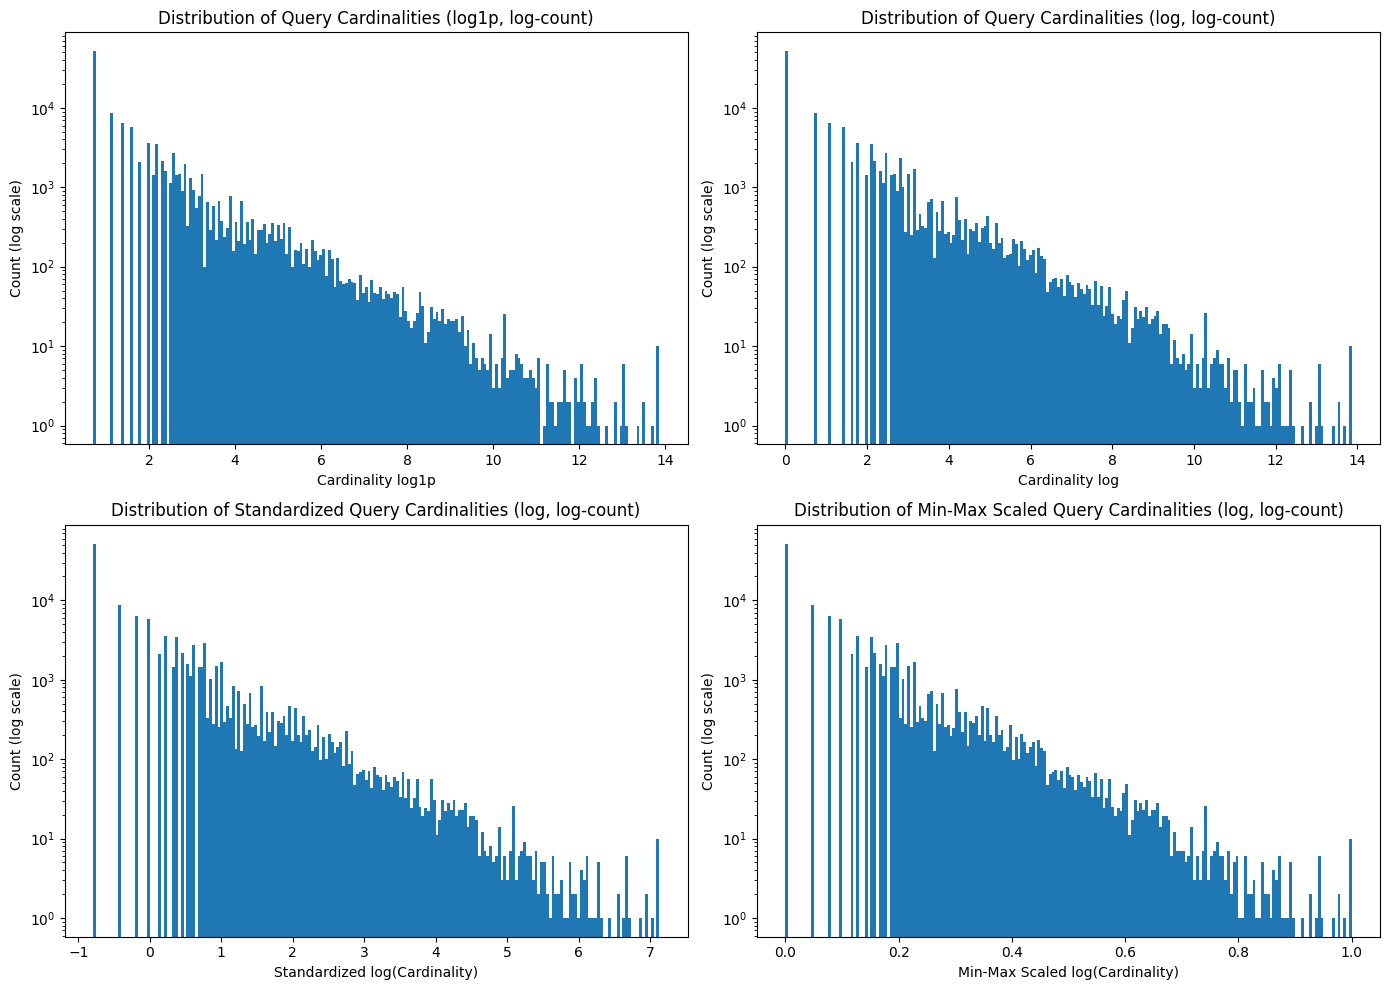

In [40]:
queries = list(queries)
cards = [q.y.item() for q in queries]
cards_log1p = np.log1p(cards)
cards_log = np.log(cards)
cards_standardized = (cards_log - np.mean(cards_log)) / np.std(cards_log)

cards_min_max = (cards_log - np.min(cards_log)) / (np.max(cards_log) - np.min(cards_log))

import matplotlib.pyplot as plt

fig, axs = plt.subplots(2, 2, figsize=(14, 10))

axs[0, 0].hist(cards_log1p, bins=200, log=True)
axs[0, 0].set_xlabel("Cardinality log1p")
axs[0, 0].set_ylabel("Count (log scale)")
axs[0, 0].set_title("Distribution of Query Cardinalities (log1p, log-count)")

axs[0, 1].hist(cards_log, bins=200, log=True)
axs[0, 1].set_xlabel("Cardinality log")
axs[0, 1].set_ylabel("Count (log scale)")
axs[0, 1].set_title("Distribution of Query Cardinalities (log, log-count)")

axs[1, 0].hist(cards_standardized, bins=200, log=True)
axs[1, 0].set_xlabel("Standardized log(Cardinality)")
axs[1, 0].set_ylabel("Count (log scale)")
axs[1, 0].set_title("Distribution of Standardized Query Cardinalities (log, log-count)")

axs[1, 1].hist(cards_min_max, bins=200, log=True)
axs[1, 1].set_xlabel("Min-Max Scaled log(Cardinality)")
axs[1, 1].set_ylabel("Count (log scale)")
axs[1, 1].set_title("Distribution of Min-Max Scaled Query Cardinalities (log, log-count)")

plt.tight_layout()
plt.show()
